**Required libraries**

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

**Dataset load (Q5-a)**

In [14]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)

print("\nClass Distribution:")
print(pd.Series(y).map({
    0: "Malignant",
    1: "Benign"
}).value_counts())

print("\nFirst Five Rows:")
display(X.head())

print("\nTarget Classes:", data.target_names)

Dataset Shape: (569, 30)

Class Distribution:
Benign       357
Malignant    212
Name: count, dtype: int64

First Five Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target Classes: ['malignant' 'benign']


**Splitting training and testing data**

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 455
Testing Samples: 114


**Gaussian Naïve Bayes (Q5-b)**

In [16]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

train_pred = nb_model.predict(X_train)
test_pred = nb_model.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Test Accuracy:",
      accuracy_score(y_test, test_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Training Accuracy: 0.9406593406593406
Test Accuracy: 0.9385964912280702
Confusion Matrix:
[[38  4]
 [ 3 69]]


**Decision Tree (Q5-c)**

In [17]:
depths = [1, 2, 3, 5, 8, None]

train_accuracies = []
test_accuracies = []
models = {}

for depth in depths:
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_acc = accuracy_score(
        y_test, model.predict(X_test)
    )

    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)
    models[depth] = model

    print(
        f"Depth: {depth}, "
        f"Training Accuracy: {train_acc:.4f}, "
        f"Test Accuracy: {test_acc:.4f}"
    )

Depth: 1, Training Accuracy: 0.9231, Test Accuracy: 0.9211
Depth: 2, Training Accuracy: 0.9582, Test Accuracy: 0.8947
Depth: 3, Training Accuracy: 0.9670, Test Accuracy: 0.9474
Depth: 5, Training Accuracy: 0.9912, Test Accuracy: 0.9298
Depth: 8, Training Accuracy: 1.0000, Test Accuracy: 0.9123
Depth: None, Training Accuracy: 1.0000, Test Accuracy: 0.9123


In [18]:
best_depth = depths[
    np.argmax(test_accuracies)
]

best_tree = models[best_depth]

print("Selected Tree Depth:", best_depth)
print("Best Test Accuracy:",
      max(test_accuracies))

Selected Tree Depth: 3
Best Test Accuracy: 0.9473684210526315


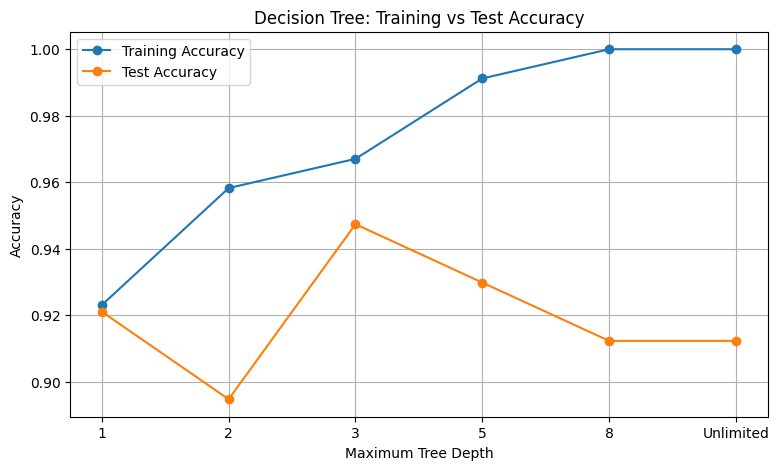

In [19]:
labels = ["1", "2", "3", "5", "8", "Unlimited"]

plt.figure(figsize=(9, 5))
plt.plot(labels, train_accuracies, marker="o",
         label="Training Accuracy")
plt.plot(labels, test_accuracies, marker="o",
         label="Test Accuracy")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Test Accuracy")
plt.legend()
plt.grid(True)
plt.show()

**Best Tree aur Top 3 Features (Q5-d)**

In [20]:
best_depth = depths[
    np.argmax(test_accuracies)
]

best_tree = models[best_depth]

print("Selected Tree Depth:", best_depth)
print("Best Test Accuracy:",
      max(test_accuracies))

Selected Tree Depth: 3
Best Test Accuracy: 0.9473684210526315


**Tree visualize**

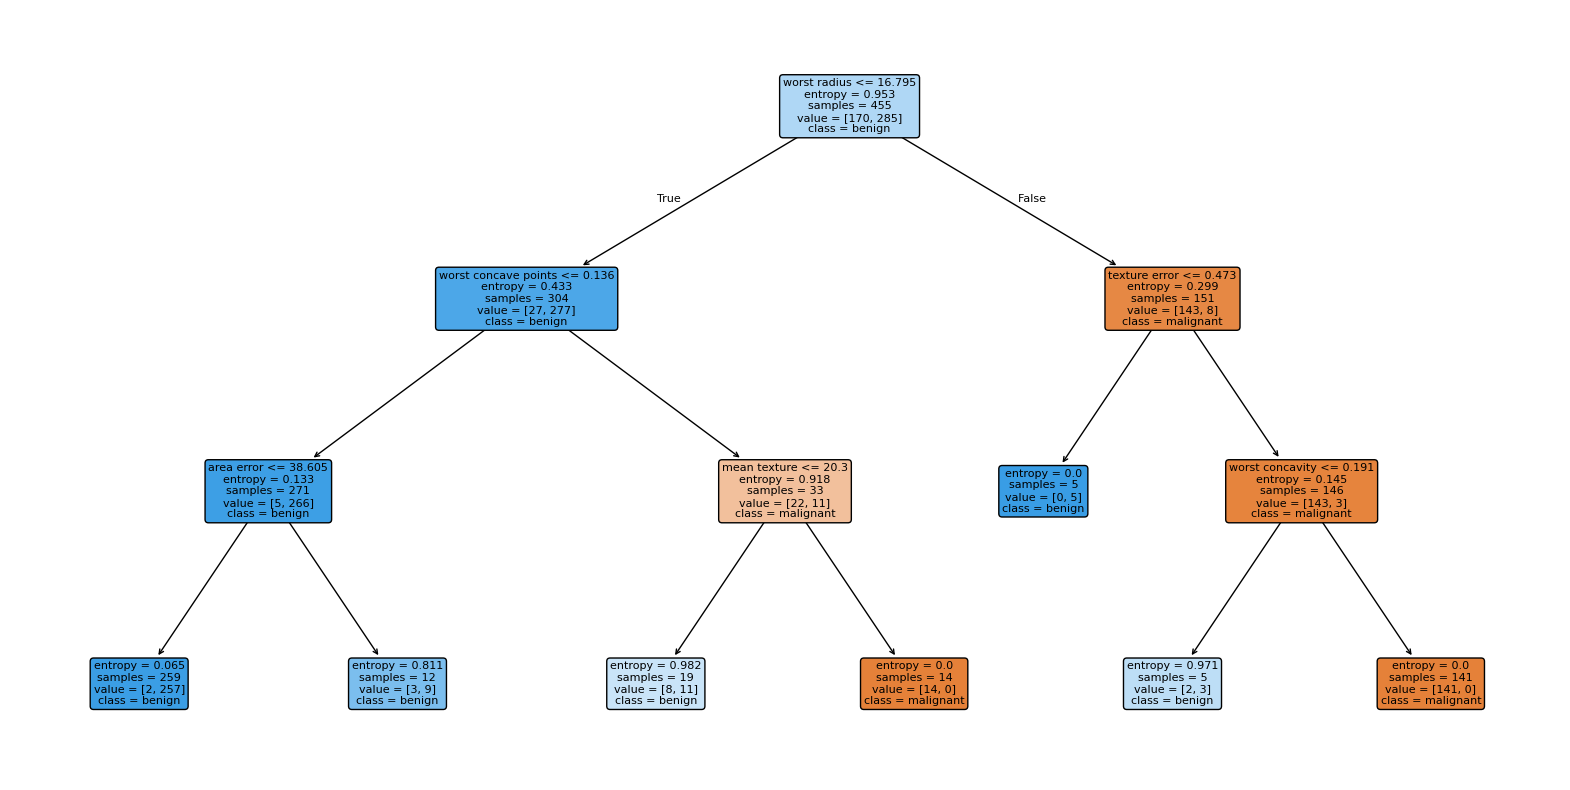

In [21]:
plt.figure(figsize=(20, 10))

plot_tree(
    best_tree,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.show()

**Top 03 features**

In [23]:
importance = pd.Series(
    best_tree.feature_importances_,
    index=data.feature_names
).sort_values(ascending=False)

print("Top 3 Important Features:")
display(importance.head(3))

Top 3 Important Features:


worst radius            0.670365
worst concave points    0.170025
texture error           0.062660
dtype: float64

The decision tree achieves its highest test accuracy at depth 3 (94.74%). As the tree depth increases beyond this point, training accuracy continues to improve while test accuracy decreases. This indicates overfitting because the deeper tree learns the training data more closely but generalizes less effectively to unseen data.

**Q6. Ensemble Methods**
This section compares Random Forest, AdaBoost, XGBoost (or Gradient Boosting if XGBoost is unavailable), and Stacking using the same 80/20 train-test split used in Q5.

**Q6(a) Train ensemble models and evaluate them**
The evaluation metrics are test accuracy, precision, recall, and F1-score. For this dataset, class 0 is malignant and class 1 is benign. The metrics below use average="binary", pos_label=0 so precision and recall specifically measure detection of malignant cases.

In [24]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# AdaBoost with decision stumps (trees of depth 1)
stump = DecisionTreeClassifier(max_depth=1, random_state=42)
try:
    ada_model = AdaBoostClassifier(estimator=stump, n_estimators=100, random_state=42)
except TypeError:  # Compatibility with older scikit-learn versions
    ada_model = AdaBoostClassifier(base_estimator=stump, n_estimators=100, random_state=42)

# XGBoost if installed; otherwise use GradientBoostingClassifier
try:
    from xgboost import XGBClassifier
    xgb_model = XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9,
        objective="binary:logistic", eval_metric="logloss",
        random_state=42, n_jobs=1
    )
    xgb_name = "XGBoost"
except ImportError:
    xgb_model = GradientBoostingClassifier(random_state=42)
    xgb_name = "Gradient Boosting (XGBoost unavailable)"

# Stacking: GaussianNB, decision tree, and Random Forest; Logistic Regression as final estimator
stack_model = StackingClassifier(
    estimators=[
        ("naive_bayes", GaussianNB()),
        ("decision_tree", DecisionTreeClassifier(random_state=42)),
        ("random_forest", RandomForestClassifier(n_estimators=100, random_state=42))
    ],
    final_estimator=LogisticRegression(max_iter=2000, random_state=42),
    cv=5,
    n_jobs=1
)

ensemble_models = {
    "Random Forest": rf_model,
    "AdaBoost": ada_model,
    xgb_name: xgb_model,
    "Stacking": stack_model
}

ensemble_results = {}
for name, model in ensemble_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    ensemble_results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Malignant)": precision_score(y_test, predictions, pos_label=0, zero_division=0),
        "Recall (Malignant)": recall_score(y_test, predictions, pos_label=0, zero_division=0),
        "F1-score (Malignant)": f1_score(y_test, predictions, pos_label=0, zero_division=0)
    }

ensemble_results_df = pd.DataFrame(ensemble_results).T
print("Test-set performance of ensemble models:")
display(ensemble_results_df.round(4))

Test-set performance of ensemble models:


,Accuracy,Precision (Malignant),Recall (Malignant),F1-score (Malignant)
Random Forest,0.9561,0.9512,0.9286,0.9398
AdaBoost,0.9561,0.9744,0.9048,0.9383
Gradient Boosting (XGBoost unavailable),0.9561,0.9744,0.9048,0.9383
Stacking,0.9474,0.9500,0.9048,0.9268


**Q6(b) Comparison table including Q5 models**
The comparison includes Gaussian Naïve Bayes and the best decision tree selected in Q5, alongside the four ensemble models.

In [25]:
comparison_results = {
    "Gaussian Naive Bayes": {
        "Accuracy": accuracy_score(y_test, nb_model.predict(X_test)),
        "Precision (Malignant)": precision_score(y_test, nb_model.predict(X_test), pos_label=0, zero_division=0),
        "Recall (Malignant)": recall_score(y_test, nb_model.predict(X_test), pos_label=0, zero_division=0),
        "F1-score (Malignant)": f1_score(y_test, nb_model.predict(X_test), pos_label=0, zero_division=0)
    },
    f"Decision Tree (depth={best_depth if best_depth is not None else 'unlimited'})": {
        "Accuracy": accuracy_score(y_test, best_tree.predict(X_test)),
        "Precision (Malignant)": precision_score(y_test, best_tree.predict(X_test), pos_label=0, zero_division=0),
        "Recall (Malignant)": recall_score(y_test, best_tree.predict(X_test), pos_label=0, zero_division=0),
        "F1-score (Malignant)": f1_score(y_test, best_tree.predict(X_test), pos_label=0, zero_division=0)
    }
}
comparison_results.update(ensemble_results)
comparison_df = pd.DataFrame(comparison_results).T.sort_values("Accuracy", ascending=False)
print("Comparison of Q5 and Q6 models (malignant class is positive for precision/recall/F1):")
display(comparison_df.round(4))

Comparison of Q5 and Q6 models (malignant class is positive for precision/recall/F1):


,Accuracy,Precision (Malignant),Recall (Malignant),F1-score (Malignant)
AdaBoost,0.9561,0.9744,0.9048,0.9383
Random Forest,0.9561,0.9512,0.9286,0.9398
Gradient Boosting (XGBoost unavailable),0.9561,0.9744,0.9048,0.9383
Decision Tree (depth=3),0.9474,0.9500,0.9048,0.9268
Stacking,0.9474,0.9500,0.9048,0.9268
Gaussian Naive Bayes,0.9386,0.9268,0.9048,0.9157


**Q6(c) Top 10 Random Forest feature importances**

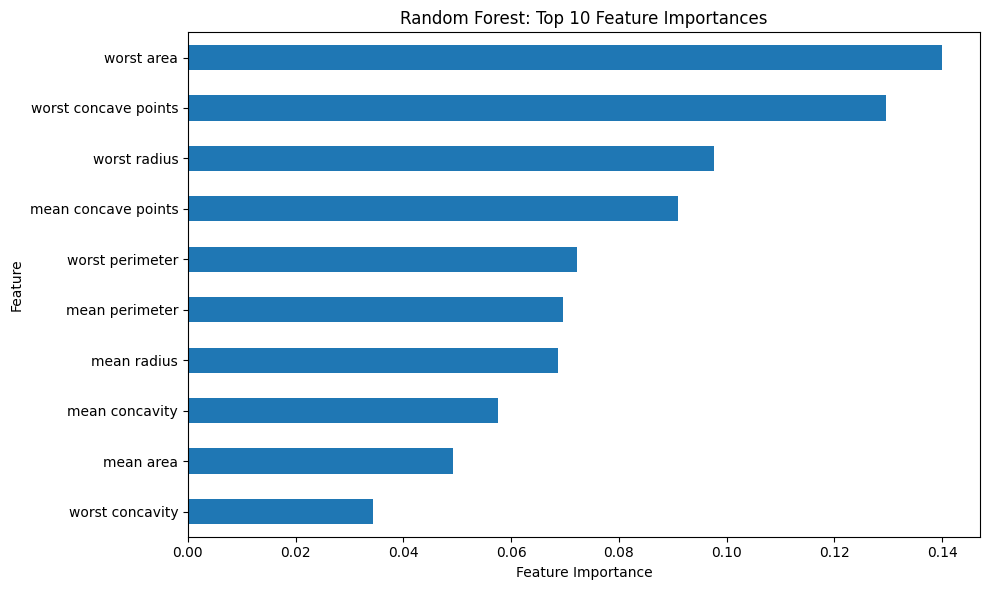

Top 10 Random Forest features:


,Importance
worst area,0.1400
worst concave points,0.1295
worst radius,0.0977
mean concave points,0.0909
worst perimeter,0.0722
mean perimeter,0.0696
mean radius,0.0687
mean concavity,0.0576
mean area,0.0492
worst concavity,0.0343


In [26]:
rf_importance = pd.Series(rf_model.feature_importances_, index=data.feature_names).sort_values(ascending=False)
top10_rf = rf_importance.head(10).sort_values()

plt.figure(figsize=(10, 6))
top10_rf.plot(kind="barh")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest: Top 10 Feature Importances")
plt.tight_layout()
plt.show()

print("Top 10 Random Forest features:")
display(rf_importance.head(10).to_frame(name="Importance").round(4))

**Q6(d) Short analysis**
Use the measured results in the comparison table to identify the strongest model. The following text is generated from the actual test-set results, rather than assuming a particular model wins.

In [27]:
best_model_name = comparison_df["Accuracy"].idxmax()
best_model_row = comparison_df.loc[best_model_name]

analysis = (
    f"Based on the held-out test set, {best_model_name} achieved the highest accuracy "
    f"({best_model_row['Accuracy']:.2%}) among the evaluated models. Ensemble methods combine "
    "multiple learners, which can improve generalization compared with a single decision tree. "
    "Random Forest trains many trees on randomized samples and features, helping reduce variance. "
    "Boosting builds learners sequentially so later learners focus more on earlier errors, while "
    "stacking learns how to combine predictions from different base models. Their performance "
    "still depends on the data and settings, so the comparison metrics should be considered together. "
    "For a medical screening task, recall for the malignant class is especially important because "
    "a false negative means a malignant case is missed. Precision also matters, since false positives "
    "can cause anxiety and additional testing. Therefore, I would prioritize high malignant-class recall "
    "while also checking precision, F1-score, and the confusion matrix. These models are educational "
    "comparisons and should not be used for clinical decisions without further validation."
)
print(analysis)
print("\nMalignant-class recall by model:")
display(comparison_df[["Recall (Malignant)", "Precision (Malignant)", "F1-score (Malignant)"]].sort_values("Recall (Malignant)", ascending=False).round(4))

Based on the held-out test set, AdaBoost achieved the highest accuracy (95.61%) among the evaluated models. Ensemble methods combine multiple learners, which can improve generalization compared with a single decision tree. Random Forest trains many trees on randomized samples and features, helping reduce variance. Boosting builds learners sequentially so later learners focus more on earlier errors, while stacking learns how to combine predictions from different base models. Their performance still depends on the data and settings, so the comparison metrics should be considered together. For a medical screening task, recall for the malignant class is especially important because a false negative means a malignant case is missed. Precision also matters, since false positives can cause anxiety and additional testing. Therefore, I would prioritize high malignant-class recall while also checking precision, F1-score, and the confusion matrix. These models are educational comparisons and shou

,Recall (Malignant),Precision (Malignant),F1-score (Malignant)
Random Forest,0.9286,0.9512,0.9398
AdaBoost,0.9048,0.9744,0.9383
Gradient Boosting (XGBoost unavailable),0.9048,0.9744,0.9383
Decision Tree (depth=3),0.9048,0.9500,0.9268
Stacking,0.9048,0.9500,0.9268
Gaussian Naive Bayes,0.9048,0.9268,0.9157
